# <font color="orange"> Análisis de los datos a la universidad </font>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

### Apartado 1.1


In [3]:
cols = ['des_universidad', 'curso_academico', 'cod_titulacion', 'des_titulacion',
        'des_forma_admision', 'nota_admision', 'ind_se_matricula_en_primero', 'ind_accede_al_SUE_por_1a_vez']

df_uam = pd.read_csv('uam2425.csv', usecols=cols, decimal=",")
df_ucm = pd.read_csv('ucm2425.csv', usecols=cols, decimal=",")
df_ujrc = pd.read_csv('urjc2425.csv', usecols=cols, decimal=",")

df_uni = [df_uam, df_ucm, df_ujrc]

for uni in df_uni:
    for column in uni:
        uni.dropna(how='all', axis=1, inplace=True)
        


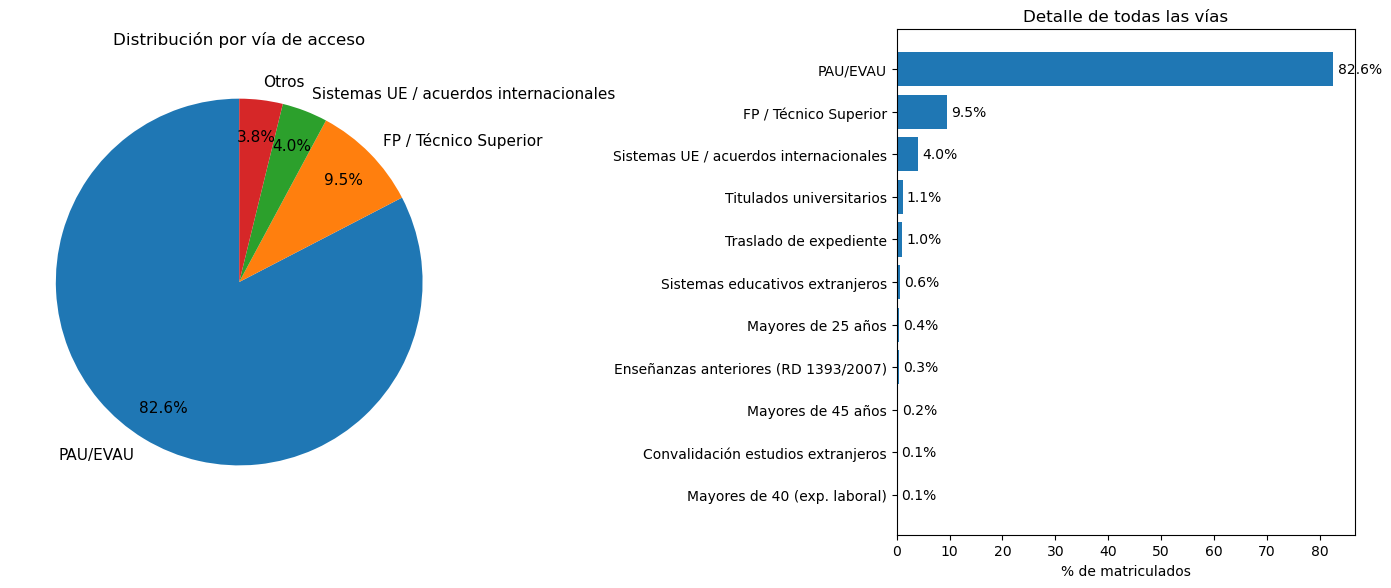

In [4]:
nombre = 'des_forma_admision'

nombres_cortos = {
	'Pruebas de Acceso': 'PAU/EVAU',
	'Técnica/o Superior': 'FP / Técnico Superior',
	'otro título universitario': 'Titulados universitarios',
	'sistemas miembros de la Unión Europea': 'Sistemas UE / acuerdos internacionales',
	'enseñanzas anteriores': 'Enseñanzas anteriores (RD 1393/2007)',
	'Mayores de 25': 'Mayores de 25 años',
	'Mayores de 45': 'Mayores de 45 años',
	'Mayores de 40': 'Mayores de 40 (exp. laboral)',
	'traslado de Expediente': 'Traslado de expediente',
	'homologación': 'Sistemas educativos extranjeros',
	'Convalidación parcial': 'Convalidación estudios extranjeros',
}

def renombrar(via):
	for clave, corto in nombres_cortos.items():
		if clave in via:
			return corto
	return via

total = pd.concat([
	df_uam[nombre],
	df_ucm[nombre],
	df_ujrc[nombre]
]).map(renombrar).value_counts()

pct = total / total.sum() * 100

# Pie: vías >= 2 % + "Otros"
pie_data = pct[pct >= 2].copy()
pie_data['Otros'] = pct[pct < 2].sum()

fig, (ax_pie, ax_bar) = plt.subplots(1, 2, figsize=(14, 6))

ax_pie.pie(pie_data.values, labels=pie_data.index,
           autopct='%1.1f%%', startangle=90, pctdistance=0.8,
           textprops={'fontsize': 11})
ax_pie.set_title('Distribución por vía de acceso')

barras = pct.sort_values()
bars = ax_bar.barh(barras.index, barras.values)
ax_bar.bar_label(bars, fmt='%.1f%%', padding=3)
ax_bar.set_xlabel('% de matriculados')
ax_bar.set_title('Detalle de todas las vías')

fig.tight_layout()

#### Justificación del diseño

- **Tipo de gráfico:** combinamos un diagrama circular y un diagrama de barras horizontales. El circular sirve para ver de un vistazo qué parte del total representa cada vía (son porcentajes que suman 100 %). Las barras permiten comparar con precisión todas las vías, incluidas las muy minoritarias, que en el circular serían porciones imposibles de distinguir.
- **Agrupación "Otros":** en el circular, las vías por debajo del 2 % se agrupan en "Otros" para que no se solapen las etiquetas. En las barras se muestran todas, así no se pierde información.

- **Leyenda:** No incluimos leyenda pues es suficentemente legible una vez acortados los nombres.

### <span style="color: blue;">¿Qué vía de acceso agrupa a la mayor proporción de matriculados?</span>

Las Pruebas de Acceso a la Universidad (EVAU, PAU y pruebas anteriores), con un 82,6 % de los 33.428 matriculados de las tres universidades. Esto supone más de 4 de cada 5 estudiantes, muy por encima de todas las demás vías juntas (17,4 %).

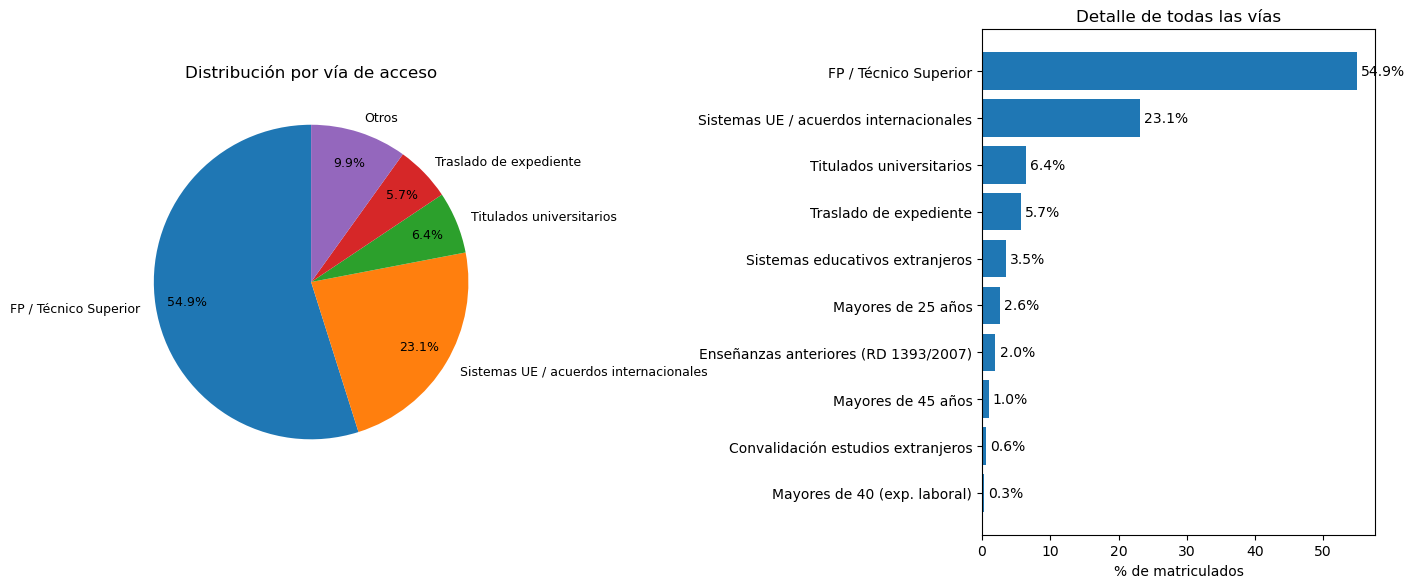

In [5]:
total2 = total.iloc[1:]

pct = total2 / total2.sum() * 100

# Pie: vías >= 2 % + "Otros"
pie_data = pct[pct >= 4].copy()
pie_data['Otros'] = pct[pct < 4].sum()

fig, (ax_pie, ax_bar) = plt.subplots(1, 2, figsize=(14, 6))

ax_pie.pie(pie_data.values, labels=pie_data.index,
           autopct='%1.1f%%', startangle=90, pctdistance=0.8,
           textprops={'fontsize': 9})
ax_pie.set_title('Distribución por vía de acceso')

barras = pct.sort_values()
bars = ax_bar.barh(barras.index, barras.values)
ax_bar.bar_label(bars, fmt='%.1f%%', padding=3)
ax_bar.set_xlabel('% de matriculados')
ax_bar.set_title('Detalle de todas las vías')

fig.tight_layout()


#### Justificación del diseño

Repetimos la misma combinación de circular y barras, pero recalculando los porcentajes sobre el total de estudiantes que no entran por PAU/EVAU. El umbral de "Otros" del circular sube al 4 % porque, al quitar la vía principal, hay más categorías pequeñas que antes compartían el mismo espacio.

### <span style="color: blue;">Si excluyes esa vía principal, ¿qué otro cupo destaca sobre los demás? ¿Tuviste que tomar alguna decisión de diseño en tu gráfico para poder visualizar y comparar correctamente estos cupos minoritarios?</span>

Destaca el acceso por títulos de Técnico Superior (FP, Enseñanzas Artísticas y Deportivas): supone un 9,5 % del total, y casi 55 % de los accesos que no son por PAU/EVAU. Le siguen, a bastante distancia, los estudiantes de sistemas de la UE o con acuerdos internacionales (4,0 % del total, 23 % de los no-PAU). El resto de cupos (titulados, traslados, mayores de 25/40/45, homologaciones…) no llegan al 1,2 % cada uno. Notese que aplicamos un umbral que agrupa los cupos de menor representación que 2%.


### Apartado 1.2

In [6]:
#

rama = pd.read_excel('rama-campo.xlsx', sheet_name='Titulación_Rama', header=5, usecols=[4, 8])  

rama.columns=['cod_titulacion', 'rama']
rama['cod_titulacion'] = pd.to_numeric(rama['cod_titulacion'], errors='coerce')
rama = rama.dropna().drop_duplicates('cod_titulacion')
rama['cod_titulacion'] = rama['cod_titulacion'].astype('int64')

def cargar(fichero):
    df = pd.read_csv(fichero, usecols=cols, decimal=',')
    df['cod_titulacion'] = df['cod_titulacion'].astype('Int64')
    return df.merge(rama, on='cod_titulacion', how='left')

df_uam  = cargar('uam2425.csv')
df_ucm  = cargar('ucm2425.csv')
df_ujrc = cargar('urjc2425.csv')

df_total = pd.concat([df_uam, df_ucm, df_ujrc])
df_total.dropna(subset=['rama'])
acceso = {}
for r, grupo in df_total.groupby('rama'):
    si = (grupo['ind_se_matricula_en_primero'] == 'SÍ').sum()
    no = (grupo['ind_se_matricula_en_primero'] == 'NO').sum()
    nota_media= np.mean(grupo['nota_admision'])
    acceso[r] = {'SÍ': si, 'NO': no, 'ratio': si / (si + no), 'media':nota_media}
acceso['nota_max']={'media':14.0}


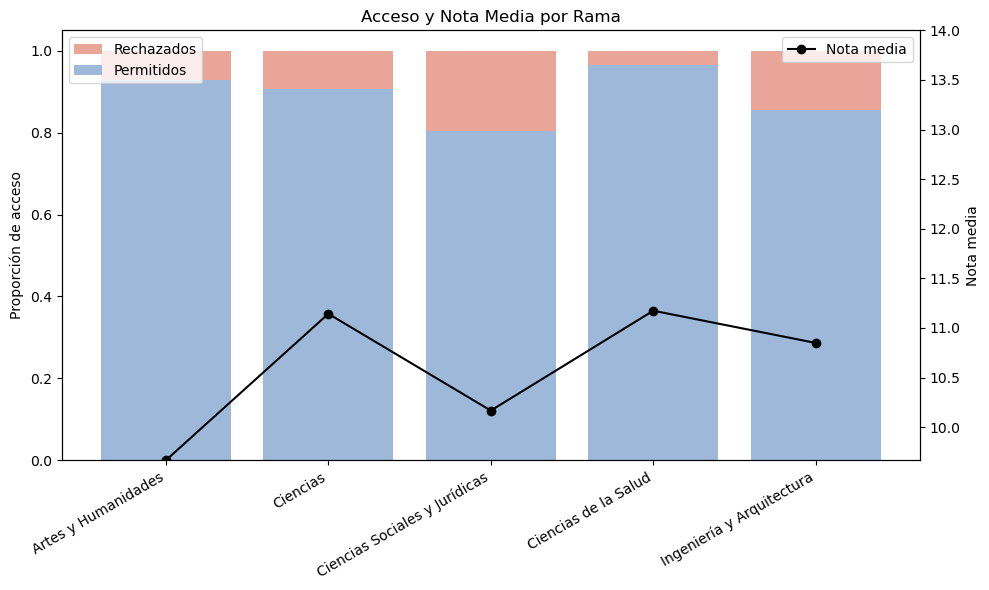

In [8]:
import pandas as pd
import matplotlib.pyplot as plt


df_plot = pd.DataFrame.from_dict(acceso, orient='index').drop('nota_max', errors='ignore')
plt.figure(figsize=(10, 6))
plt.bar(df_plot.index, 1 - df_plot['ratio'], bottom=df_plot['ratio'], color='#E8A598', label='Rechazados')
plt.bar(df_plot.index, df_plot['ratio'], color='#9DB8D9', label='Permitidos')
plt.ylabel('Proporción de acceso')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='upper left')

plt.twinx()
plt.plot(df_plot.index, df_plot['media'], color='black', marker='o', label='Nota media', )
plt.ylim(df_plot['media'].min(), 14)
plt.ylabel('Nota media')
plt.legend(loc='upper right')

plt.title("Acceso y Nota Media por Rama")
plt.tight_layout()
plt.show()

#### Justificación del diseño

- **Tipo de gráfico:** Elegimos un diagrama de barras, una barra por rama de estudio, que representa la proporción de acceso. En la propia barra podemos ver de un viztazo dicha proporción, en azul la tasa de acceso y en rojo la de rechazo, y su combinación ocupa la totalidad del rango de la barra, es decir el 100% de las solicitudes por rama. Por otra parte añadimos los puntos de la nota media en un rango del 10 al 14 para mejorar la interpretación, unidos por una linea

### <span style="color:blue;"> Comparación con informe Rtve</span>

**Fuente:** [*Las 100 carreras más demandadas y en qué universidad pública se estudian*](https://www.rtve.es/noticias/20250517/100-carreras-mas-demandadas-universidad-publica-se-estudian/16559324.shtml) (DatosRTVE, 17/05/2025), curso 2024-2025, el mismo que analizamos.

**Qué cuenta la noticia.** RTVE recopila la nota de corte más alta de cada universidad pública española y construye un ranking de las 100 titulaciones con mayor exigencia. Concluye que el top está dominado por dobles grados con Matemáticas (Física-Matemáticas lidera con un 13,764 en Sevilla; Matemáticas aparece en 32 de las 100 carreras), que Medicina es la carrera con mayor nota en 35 de las 50 universidades públicas y aparece 26 veces en el listado, y que Derecho-Relaciones Internacionales es la única titulación fuera del ámbito científico-tecnológico en el top 10. De Madrid, destaca la presencia de la URJC (7 titulaciones) y la UCM (6).

**Contraste con nuestros datos.** Los resultados coinciden en lo esencial:
- Las ramas con mayor nota media de acceso por nota son **Ciencias de la Salud (≈11,2)** y **Ciencias (≈11,2)**, seguidas de Ingeniería y Arquitectura (≈10,9). Esto encaja con un ranking dominado por Medicina, Matemáticas y Física.
- Si bajamos al nivel de titulación, las notas medias más altas de nuestras tres universidades son el Doble Grado en Matemáticas-Física de la UCM (≈13,7) y el de Ingeniería Informática-Matemáticas (≈13,3), seguidos de Medicina en la UAM y la UCM (≈13,1). Es el mismo patrón que describe RTVE.

**Qué aporta nuestra visualización frente a la noticia.**
1. **Mide algo distinto y complementario.** RTVE usa la *nota de corte*, que es la nota del último admitido, y solo la de la titulación más exigente de cada universidad. Nosotros mostramos la *nota media* de todos los admitidos por nota, que describe al estudiante típico de cada rama y no solo el umbral mínimo.
2. **Cambia la escala de análisis.** La noticia es una lista de titulaciones sueltas, mientras que nuestra figura agrega por **rama de conocimiento**. Así se ve una tendencia general que el ranking no muestra: ninguna titulación de Ciencias Sociales y Jurídicas destaca individualmente, y sin embargo es la rama que concentra con diferencia más estudiantes (≈56 % de los accesos).
3. **Añade el volumen y la tasa de acceso.** Un ranking de notas no dice cuántos estudiantes hay detrás ni cuántos acaban matriculándose. Nuestra figura combina en el mismo gráfico la exigencia (nota media) y la tasa de acceso. Por ejemplo, Ciencias de la Salud es a la vez la rama más exigente y la de mayor tasa de matriculación (≈97 %): quien consigue plaza en ella casi siempre la ocupa. En cambio, Ciencias Sociales y Jurídicas tiene la tasa más baja (≈80 %).
4. **Matiza el término "más demandadas".** La noticia usa "demandadas" como sinónimo de "nota de corte más alta", pero una nota de corte alta suele reflejar pocas plazas tanto como mucha demanda. Nuestros datos muestran que las titulaciones con más nota (dobles grados con 13-35 admitidos) son de las que menos estudiantes reciben.


